In [1]:
%pip install -q| requests pydantic python-dotenv pandas matplotlib numpy httpx langgraph langchain langchain-openai smolagents

Note: you may need to restart the kernel to use updated packages.


"requests" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


In [2]:
import os, re, json, gzip, time, warnings
os.environ.setdefault("LANGCHAIN_OPENAI_TCP_KEEPALIVE", "0")
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from typing import TypedDict
import httpx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from pymilvus import MilvusClient
from dataclasses import dataclass, field


try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
KEY = os.getenv("OPENROUTER_API_KEY")
assert KEY, "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

BASE_URL = "https://openrouter.ai/api/v1"
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("data"), Path("/kaggle/input/seminar03-data"), Path("/kaggle/input/seminar03-data/data")]
             if (p / "fresh_2026.jsonl").exists()), Path("data"))
SAMPLE, STRONG_SAMPLE = 40, 40
Path("img").mkdir(exist_ok=True)

def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

def pmap(fn, items, workers=6):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))

# Шаг 1. Счётчик и базовая линия

In [3]:
CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "X-Title": "agents-course-seminar02"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}

In [4]:
CALLS, FIRST, TAG = [], {}, {"now": "без метки"} 

In [5]:
def on_response(response):
    response.read() # объект httpx.Response
    request = json.loads(response.request.content or b"{}")
    # print(request)
    usage = response.json().get("usage") or {}
    FIRST.setdefault(TAG["now"], request)
    CALLS.append({
        "tag":TAG["now"],
        "model": request.get("model", "?").split("/")[-1],
        "messages": len(request.get("messages", [])),
        "tools": len(request.get("tools", [])),
        "prompt": usage.get("prompt_tokens", 0),
        "completion": usage.get("completion_tokens", 0),
        "cost": usage.get("cost") or 0

    })

In [8]:
for key in ("HTTP_PROXY", "HTTPS_PROXY", "ALL_PROXY", "http_proxy", "https_proxy", "all_proxy"):
    os.environ.pop(key, None)

In [9]:
HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=180)
HEADERS = {"Authorization": f"Bearer {KEY}", "X-Title": "agents-course-seminar03"}

def chat(messages, model=MODELS["cheap"], tools=None, temperature=0.0):
    body = {"model": model, "messages": messages, "temperature": temperature}
    if tools:
        body["tools"] = tools
    for attempt in range(5):
        r = HTTP.post(f"{BASE_URL}/chat/completions", json=body, headers=HEADERS)
        if r.status_code == 200:
            return r.json()["choices"][0]["message"]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")

TAG["now"] = "проверка счётчика"
chat([{"role": "user", "content": "Say OK"}])
pd.DataFrame(CALLS)

,tag,model,messages,tools,prompt,completion,cost
0,проверка счётчика,gpt-4o-mini,1,0,9,2,0.000003


### CHUNKING BY PARAGRAPHS

In [10]:
corpus, tasks_with_answer, no_answer_tasks, tasks = load_jsonl("MRC_corpus.jsonl"), load_jsonl("MRC_questions_with_answer_40.jsonl"), load_jsonl("MRC_questions_no_answer.jsonl"), load_jsonl("MRC_questions.jsonl")
len(corpus), sum(len(p["text"]) for p in corpus), len(tasks), tasks[0]

(91,
 181915,
 40,
 {'id': 'q-0',
  'source': 'MRC WHL 01-01-2026.pdf',
  'question': 'What project is being developed to identify minerals in core samples through chemical processing and iLens imaging without destroying the core?',
  'answer': 'Lens-Ore',
  'evidence': 'on, and water purification, and WasteLock - for reduction in the cost of extracting residual minerals. The next step is to develop the innovative Lens-Ore project - a hybrid system for instantly identifying minerals in core samples through a combination of chemical processing and subsequent iLens im',
  'page': 'MRC WHL 01-01-2026.pdf',
  'section': 'page. 2',
  'url': ''})

In [12]:
def chunk_paragraphs(page):
    chunks = []
    for block in re.split(r"\n\s*\n+", page["text"]):
        text = " ".join(block.split())
        if len(text) > 40:
            chunks.append({"page": page["page"], "section": page["section"], "url": page["url"], "text": text})
    return chunks

In [13]:
paragraph_chunks = [c for p in corpus for c in chunk_paragraphs(p)]

### CACHE

In [14]:
import os, re, sys, json, time, hashlib, threading
import requests


In [15]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)
    local: threading.local = field(default_factory=threading.local)

    def add(self, tag, model, usage, seconds=0.0):
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": usage.get("prompt_tokens", 0),
                           "completion": usage.get("completion_tokens", 0), "cost": cost, "seconds": round(seconds, 2)})
        self.local.spent = self.mine + cost
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    @property
    def mine(self):
        return getattr(self.local, "spent", 0.0)

    def table(self):
        frame = pd.DataFrame(self.calls, columns=["tag", "model", "prompt", "completion", "cost", "seconds"])
        return frame.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                                      completion=("completion", "sum"), cost=("cost", "sum")).round(5)


ledger = Ledger()



# def chat(messages, model, tools=None, tag="chat"):
#     body = {"model": model, "messages": messages, "temperature": 0, "usage": {"include": True}}
#     if tools:
#         body["tools"] = tools
#     started = time.perf_counter()
#     data = post_with_retry(CHAT_URL, body)
#     ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
#     return data["choices"][0]["message"]


def post_with_retry(url, body, attempts=5):
    problem = "нет ответа"
    for attempt in range(attempts):
        try:
            r = requests.post(url, json=body, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            problem = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            problem = type(e).__name__
        time.sleep(2.0 * (attempt + 1))
    raise RuntimeError(problem)




In [16]:
EMB = {}

def load_cache():
    for path in [DATA / "embeddings_512.npz", Path("emb_cache.npz")]:
        if path.exists():
            z = np.load(path)
            EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)

def save_cache():
    np.savez_compressed("emb_cache.npz", keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))

def embed_batch(texts):
    started = time.perf_counter()
    data = post_with_retry(EMBED_URL, {"model": EMBED_MODEL, "input": texts, "dimensions": DIM})
    ledger.add("embed", EMBED_MODEL, data.get("usage") or {}, time.perf_counter() - started)
    return [row["embedding"] for row in data["data"]]

def key_of(text): # хэш текста
    return hashlib.sha1(text.encode("utf-8")).hexdigest()

load_cache()

0

In [17]:
def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB)) # что нет в словаре эмбеддингов
    for i in range(0, len(missing), 64):
        batch = missing[i:i+64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.asanyarray(vector, dtype=np.float32)

    
    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors/np.linalg.norm(vectors, axis=1, keepdims=True)

In [18]:
def emb_text(chunk):
    return f"{chunk['page']}: {chunk['text']}"

paragraph_vecs = embed_cached([emb_text(c) for c in paragraph_chunks])
q_vecs = embed_cached([t["question"] for t in tasks_with_answer])
save_cache()

### MILVUS

In [19]:
MILVUS_URI = os.getenv("MILVUS_URI", "http://localhost:19530")
client = MilvusClient(uri=MILVUS_URI, token=os.getenv("MILVUS_TOKEN", ""))
if os.getenv("MILVUS_DB"):
    if os.environ["MILVUS_DB"] not in client.list_databases():
        client.create_database(os.environ["MILVUS_DB"])
    client.use_database(os.environ["MILVUS_DB"])
client.get_server_version(), client.list_collections()

('2.6.24', ['course', 'lines', 'paragraphs', 'facts'])

In [20]:
def index_to_milvus(name, chunks, vectors):
    if client.has_collection(name): # client = db
        client.drop_collection(name)
    client.create_collection(name, dimension=vectors.shape[1], metric_type="COSINE")
    rows = [{"id":i, "vector": v.tolist(), **c} for i, (c, v) in enumerate(zip(chunks, vectors))]
    for i in range(0, len(rows), 1000):
        client.insert(name, rows[i:i+1000])

    client.flush(name)
    return client.get_collection_stats(name)


In [21]:
def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search(name, data=[vector], limit=k, filter=flt, output_fields=["page", "section", "url", "text"])[0]

    return [{**h['entity'], "id": h["id"], "score": round(h["distance"], 4)} for h in hits]


In [22]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

In [23]:
class KBArgs(BaseModel):
    query: str = Field(description="short search query in English: names, dates, key terms of the event")
    page: str = Field(default="", description="optional exact page title to search within, for example 'MRC WHL 01-01-2026.pdf'; empty means all pages")

In [24]:
def knowledge_base(query: str, page: str = "") -> str:
    """Searches the local knowledge base of MRC weekly PDF reports and returns up to five closest paragraphs with their file name and section. Use page only when you know the exact PDF filename, for example 'MRC WHL 01-01-2026.pdf'."""
    flt = f"page == '{page}'" if page else ""
    hits = search_milvus("paragraphs", query, 5, flt)
    if not hits:
        return "nothing found"
    return "\n".join(f"{h['page']} / {h['section']} {h['text']}" for h in hits)

In [25]:
register(knowledge_base, KBArgs, "Searches the local knowledge base of MRC weekly PDF reports and returns up to five closest paragraphs with their file name and section. Use page only when you know the exact PDF filename, for example 'MRC WHL 01-01-2026.pdf'.")

In [26]:
knowledge_base(query=tasks_with_answer[0]["question"])

"MRC WHL 07-23-2026.pdf / page. 1 TECHNOLOGY MILESTONE ILENSE. PROTOTYPE OF ALGORITHM FOR LITHOLOGY RECOGNITION The Upstream Robotics, Sensing & Automation Team in Moscow, in collaboration with Geosciences Automation & Imaging Technology Division, has updated firmware for handheld device for geological core description. Currently this firmware allows to recognize 5 types of lithotypes with 71.5% accuracy based on photo of 1 foot long taken with iLens. This core photo is automatically cut into six 5 cm sections, for each of which the algorithm predicts a lithotype. The next step is to optimize ML-based algorithm and test by Q4/2026.\nMRC WHL 01-01-2026.pdf / page. 2 geophysical imaging. The other two projects are focused on process optimization: SoLiEx - for lithium and associated strategic mineral recovery, soil desalination, and water purification, and WasteLock - for reduction in the cost of extracting residual minerals. The next step is to develop the innovative Lens-Ore project - a

In [27]:
tasks_with_answer[0]["question"]

'What project is a hybrid system for instantly identifying minerals in core samples through chemical processing and iLens imaging?'

In [28]:
NUMBERS = {w: str(n) for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    return " ".join(NUMBERS.get(w, w) for w in re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split())

def is_correct(task, answer):
    return set(norm(task["answer"]).split()) <= set(norm(answer).split())

RESULTS = {}

def run_config(tag, fn, sample=None, workers=6):
    sample = sample 
    TAG["now"] = tag
    def one(task):
        try:
            return fn(task["question"])
        except Exception as e:
            return f"ошибка: {type(e).__name__}"
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [{"id": t["id"], "answer": a, "ok": is_correct(t, a)} for t, a in zip(sample, answers)]
    return report([tag])

def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res, calls = RESULTS[tag], [c for c in CALLS if c["tag"] == tag]
        n, ok, cost = len(res), sum(r["ok"] for r in res), sum(c["cost"] for c in calls)
        rows.append({"конфигурация": tag, "верно": f"{ok}/{n}", "доля": round(ok / n, 3), "вызовов на вопрос": round(len(calls) / n, 1),
                     "токенов на вопрос": round(sum(c["prompt"] + c["completion"] for c in calls) / n),
                     "центов на вопрос": round(cost / n * 100, 4), "центов за верный": round(cost / ok * 100, 4) if ok else None})
    return pd.DataFrame(rows)

def wrong(tag, n=10):
    return pd.DataFrame([{"эталон": t["answer"], "ответ": str(r["answer"])[:110]}
                         for t, r in zip(tasks, RESULTS[tag]) if not r["ok"]][:n])




In [29]:
def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        result = spec["fn"](**spec["args"].model_validate_json(call["function"]["arguments"]).model_dump())
    except Exception as e:
        result = f"ошибка инструмента {name}: {e}"
    return {"role": "tool", "tool_call_id": call["id"], "content": str(result)[:3000]}

AGENT_SYSTEM = ("You answer questions about MRC weekly technology reports. Never answer from memory: look facts up with the knowledge_base tool, do not repeat the same call. "
                "When done, write the last line as FINAL: <short answer>, or NOT_FOUND if the knowledge base has no answer.")

def agent(question, model, max_steps=6):
    messages, seen, before = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set(), ledger.mine
    schemas = [t["schema"] for t in TOOLS.values()]
    for step in range(max_steps):
        msg = chat(messages, model, tools=schemas)
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        keys = {(c["function"]["name"], c["function"]["arguments"]) for c in calls}
        if not calls or keys & seen or step == max_steps - 1:
            break
        seen |= keys
        messages += [run_tool(c) for c in calls]
    if calls:
        messages += [{"role": "tool", "tool_call_id": c["id"], "content": "call rejected: answer from what you already have"} for c in calls]
        msg = chat(messages, model, schemas)
    searches = sum(m.get("role") == "tool" for m in messages if isinstance(m, dict))
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before, "searches": searches}

In [31]:
out = (tasks[0]["question"], MODELS["cheap"])


In [32]:
out

('What project is being developed to identify minerals in core samples through chemical processing and iLens imaging without destroying the core?',
 'openai/gpt-4o-mini')

In [33]:
CALLS

[{'tag': 'проверка счётчика',
  'model': 'gpt-4o-mini',
  'messages': 1,
  'tools': 0,
  'prompt': 9,
  'completion': 2,
  'cost': 2.55e-06}]

In [34]:
run_config("голый цикл, mini", lambda q: agent(q, MODELS["cheap"])["answer"], sample=tasks_with_answer)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",33/40,0.825,2.1,1494,0.0257,0.0311


# Langgraph

In [35]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain.agents.middleware import wrap_model_call
from langchain_core.messages import HumanMessage

LAST_STEP = "No more tool calls. Answer now with what you found."

LC_TOOLS = [tool(knowledge_base, args_schema=KBArgs)]
LG_MIDDLEWARE = []

def lc_model(model=MODELS["cheap"], temperature=0.0):
    return ChatOpenAI(model=model, base_url=BASE_URL, api_key=KEY, http_client=HTTP, temperature=temperature) #!

In [36]:
@wrap_model_call # говорит агенту: перед каждым вызовом модели сначала выполни эту функцию.
def last_step_without_tools(request, handler):
    if sum(m.type == 'ai' for m in request.messages) >= 5:
        request = request.override(tools=[], messages=request.messages + [HumanMessage(LAST_STEP)]) # то что наговорил + последний запрос
    return handler(request)
    

In [37]:
def run_langgraph(question, model=MODELS["cheap"], temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM + extra, middleware=LG_MIDDLEWARE)
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        {"recursion_limit": 14}
    )
    return out["messages"]

In [38]:
def ask_langgraph(question, model=MODELS["cheap"], temperature=0.0, extra=""):
    return run_langgraph(question, model, temperature, extra)[-1].content

In [39]:
run_config("LangGraph, mini", lambda q: ask_langgraph(q, MODELS["cheap"]), sample=tasks_with_answer)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",35/40,0.875,2.1,1785,0.029,0.0332


#### Фраза для отчёта: LangGraph сам собрал тот же цикл и сохранил описания аргументов, но на этих 40 вопросах дал на 2 верных ответа больше при тех же 2.1 вызовах, за это и оплачены лишние токены и более высокая цена. Голый цикл обрезает историю которую кладет в запросы, LangGraph - нет

In [40]:
PROBE = "What is 2 + 2? Reply with the number only."

TAG["now"] = "пустой вопрос: голый цикл"
agent(PROBE, MODELS["cheap"])



{'answer': '4', 'hits': [], 'cost': 0.0, 'searches': 0}

In [41]:
TAG["now"] = "пустой вопрос: LangGraph"
ask_langgraph(PROBE)

'4'

In [42]:
for tag in ["пустой вопрос: голый цикл", "пустой вопрос: LangGraph"]:
    first = next(c for c in CALLS if c["tag"] == tag)
    print(tag, "вход", first["prompt"], "выход", first["completion"], "tools", first["tools"])

пустой вопрос: голый цикл вход 223 выход 2 tools 1
пустой вопрос: LangGraph вход 213 выход 2 tools 1


In [43]:
for tag in ["пустой вопрос: голый цикл", "пустой вопрос: LangGraph"]:
    tools = FIRST[tag]["tools"]
    props = tools[0]["function"]["parameters"]["properties"]
    print("\n==", tag)
    print("description:", tools[0]["function"].get("description"))
    print("query:", props["query"].get("description"))
    print("page:", props["page"].get("description"))
    # print(json.dumps(tools, ensure_ascii=False, indent=2))


== пустой вопрос: голый цикл
description: Searches the local knowledge base of MRC weekly PDF reports and returns up to five closest paragraphs with their file name and section. Use page only when you know the exact PDF filename, for example 'MRC WHL 01-01-2026.pdf'.
query: short search query in English: names, dates, key terms of the event
page: optional exact page title to search within, for example 'MRC WHL 01-01-2026.pdf'; empty means all pages

== пустой вопрос: LangGraph
description: Searches the local knowledge base of MRC weekly PDF reports and returns up to five closest paragraphs with their file name and section. Use page only when you know the exact PDF filename, for example 'MRC WHL 01-01-2026.pdf'.
query: short search query in English: names, dates, key terms of the event
page: optional exact page title to search within, for example 'MRC WHL 01-01-2026.pdf'; empty means all pages


In [44]:
for tag in ["пустой вопрос: голый цикл", "пустой вопрос: LangGraph"]:
    first = next(c for c in CALLS if c["tag"] == tag)
    print(tag, "вход", first["prompt"], "выход", first["completion"])

пустой вопрос: голый цикл вход 223 выход 2
пустой вопрос: LangGraph вход 213 выход 2


на простом вопросе фреймворк отправил тот же инструмент с теми же описаниями аргументов и потратил на 10 входных токенов меньше, так что первый запрос этих токенов не стоит. Падение на последнем шаге этими двумя числами не видно.

# Шаг 3. Два паттерна недели


## Критик с опорой

In [45]:
from langgraph.graph import StateGraph, START, END

In [46]:
class QA(TypedDict):
    question: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    checks: int

class Verdict(BaseModel): # возвращает описание поля, а BaseModel при создании класса забирает эти описания и строит из них схему.
    supported: bool = Field(description="true only if the evidence explicitly supports the answer")
    issue: str = Field(description="what is wrong or missing, empty if supported") # проблема

CRITIC_SYSTEM = (
    "You check a short answer against the paragraphs the agent retrieved from MRC weekly PDF reports. "
    "Judge only by that evidence. If the evidence does not contain the answer, the answer is not supported."
)
def answer_node(state):
    note = ""
    if state["feedback"]: # если есть фидбек
        note = f"\n\nA reviewer rejected your previous answer '{state['answer']}': {state['feedback']} Search again and correct it."
    messages = run_langgraph(state["question"] + note)
    found = "\n".join(str(m.content)[:800] for m in messages if m.type == "tool")
    return {"answer": messages[-1].content, "evidence": found[-4000:], "rounds": state["rounds"] + 1}

In [47]:
def critic_node(state):
    judge = lc_model(MODELS["cheap"]).with_structured_output(Verdict) # модель  обязана ответить 2мя полями
    verdict = judge.invoke([ # вызвать
        ("system", CRITIC_SYSTEM),
        ("user", f"Question: {state['question']}\nAnswer: {state['answer']}\n"
                 f"Evidence the agent found:\n{state['evidence'] or 'nothing'}")
    ])
    return {"feedback": "" if verdict.supported else verdict.issue, "checks": state["checks"] + 1}

In [48]:
def route(state):
    if state["feedback"] and state["rounds"] < 2:
        return 'answer'
    return END

In [49]:
graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])
checked = graph.compile()
print(checked.get_graph().draw_mermaid())



---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [50]:
def ask_checked(question):
    return checked.invoke({"question": question, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})["answer"]

In [51]:
run_config("LangGraph + критик, mini", ask_checked, sample=tasks_with_answer)
base, crit = RESULTS["LangGraph, mini"], RESULTS["LangGraph + критик, mini"]
fixed = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
broken = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))
print("исправил", fixed, "| испортил", broken)
report(["LangGraph, mini", "LangGraph + критик, mini"])

исправил 0 | испортил 1


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",35/40,0.875,2.1,1785,0.0290,0.0332
1,"LangGraph + критик, mini",34/40,0.850,3.7,2789,0.0404,0.0475


##  Голосование и каскад

In [52]:
def bag(answer):
    return " ".join(sorted(norm(answer).split()))

In [53]:
def final_answer(text):
    m = re.findall(r"FINAL:\s*(.+)", text or "")
    return m[-1].strip() if m else (text or "").strip()

In [54]:
def vote(question, k=3):
    with ThreadPoolExecutor(k) as ex:
        answers = list(ex.map(lambda _: ask_langgraph(question, MODELS["cheap"], 0.7), range(k)))
    # keys = [bag(a) for a in answers]
    keys = [bag(final_answer(a)) for a in answers]
    top, n = Counter(keys).most_common(1)[0]
    return {"answer": answers[keys.index(top)], "agreement": n / k}


In [55]:
ESCALATED = []

def cascade(question):
    v = vote(question, 3)
    if v["agreement"] == 1:
        return v["answer"]
    ESCALATED.append(question)
    return ask_langgraph(question, MODELS["strong"])
    

In [56]:
run_config("голосование 3, mini", lambda q: vote(q, 3)["answer"], sample=tasks_with_answer)
run_config("каскад: 3 голоса mini, иначе Sonnet", cascade, sample=tasks_with_answer)
run_config("LangGraph, Sonnet", lambda q: ask_langgraph(q, MODELS["strong"]), sample=tasks_with_answer)
print("ушло наверх:", len(ESCALATED), "из", len(tasks_with_answer))
report(["LangGraph, mini", "голосование 3, mini", "каскад: 3 голоса mini, иначе Sonnet", "LangGraph, Sonnet"])

ушло наверх: 13 из 40


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",35/40,0.875,2.1,1785,0.0290,0.0332
1,"голосование 3, mini",35/40,0.875,6.3,5035,0.0793,0.0906
2,"каскад: 3 голоса mini, иначе Sonnet",36/40,0.900,6.9,5940,0.5150,0.5722
3,"LangGraph, Sonnet",37/40,0.925,2.1,3560,1.4548,1.5728


In [57]:
def review(tag, n=15):
    rows = [{"вопрос": t["question"], "эталон": t["answer"], "ответ": r["answer"]}
            for t, r in zip(tasks_with_answer, RESULTS[tag]) if not r["ok"]]
    pd.set_option('display.max_colwidth', None)   # не обрезать длину ячейки
    pd.set_option('display.max_columns', None)    # показывать все колонки
    pd.set_option('display.max_rows', None)       # показывать все строки
    pd.set_option('display.width', None)          # не подгонять под ширину консоли
    pd.set_option('display.expand_frame_repr', False)  # не переносить на новую строку 
    return pd.DataFrame(rows[:n])

review("LangGraph, mini")

,вопрос,эталон,ответ
0,What system demonstrated stable and robust communication during field tests in Dhahran?,Swarm Control Station,"The system that demonstrated stable and robust communication during field tests in Dhahran is the wireless telecommunication architecture designed for the robotic seismic exploration system comprising ASAD and SeisRover. This system successfully maintained reliable wireless connectivity over distances of several kilometers during indoor testing, confirming its feasibility for further field evaluation. \n\nFINAL: ASAD - SeisRover system"
1,What system enables network-based interaction between ASADs and operators in the field and command center?,Unified Control System,"The system that enables network-based interaction between ASADs and operators in the field and command center is a wireless telecommunication architecture designed for a robotic seismic exploration system, which includes ASAD and SeisRover. This system uses SeisRover as a mobile relay station integrated with long-range directional backbone radio channels to maintain reliable wireless connectivity over distances of several kilometers.\n\nFINAL: wireless telecommunication architecture with SeisRover"
2,What design was optimized for serial production under BI-50 and involved modifications to enhance airframe strength?,ASAD2.0,ошибка: GraphRecursionError
3,What computational module aims at prediction and optimization of CO2 sequestration and was completed by the Technology Division?,interfacial tension,"The computational module that aims at prediction and optimization of CO2 sequestration, completed by the Technology Division, is the ""Predictor of Fluid Properties for Planning CO2 Sequestration in Deep Saline Aquifers."" This model predicts the amount of CO2 that can be injected at given pressure and is a necessary step towards reservoir scale planning of CCUS efforts.\n\nFINAL: Predictor of Fluid Properties for Planning CO2 Sequestration in Deep Saline Aquifers"
4,What nanomaterials were assessed for rock surface treatment to mitigate condensate banking?,fluorinated modifiers,"The assessment for rock surface treatment to mitigate condensate banking focused on fluorinated nanomaterials, which were identified as having the highest potential to reduce condensate blockage and enhance mobility. The next step involves experimental validation on model rock samples using laboratory synthesized nanomaterials by Q4/2026.\n\nFINAL: fluorinated nanomaterials"


In [58]:
TAGS = [
    "голый цикл, mini",
    "LangGraph, mini",
    "голосование 3, mini",
    "LangGraph + критик, mini",
    "каскад: 3 голоса mini, иначе Sonnet",
    "LangGraph, Sonnet",
]
table = report(TAGS)
table

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",33/40,0.825,2.1,1494,0.0257,0.0311
1,"LangGraph, mini",35/40,0.875,2.1,1785,0.0290,0.0332
2,"голосование 3, mini",35/40,0.875,6.3,5035,0.0793,0.0906
3,"LangGraph + критик, mini",34/40,0.850,3.7,2789,0.0404,0.0475
4,"каскад: 3 голоса mini, иначе Sonnet",36/40,0.900,6.9,5940,0.5150,0.5722
5,"LangGraph, Sonnet",37/40,0.925,2.1,3560,1.4548,1.5728


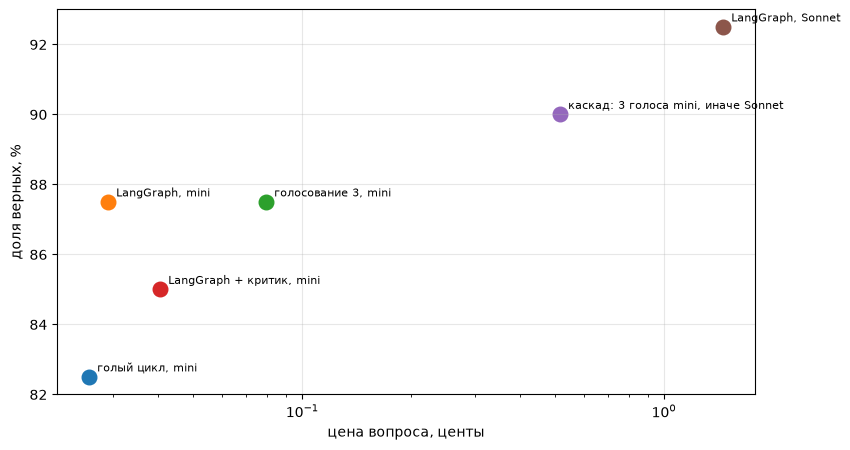

In [59]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xscale("log")
for _, r in table.iterrows():
    ax.scatter(r["центов на вопрос"], r["доля"] * 100, s=110)
    ax.annotate(r["конфигурация"], (r["центов на вопрос"], r["доля"] * 100),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("цена вопроса, центы")
ax.set_ylabel("доля верных, %")
ax.grid(alpha=0.3)
fig.savefig("img/money_all.png", dpi=150, bbox_inches="tight")

In [60]:
from langchain.agents.middleware import ModelCallLimitMiddleware

t = tasks_with_answer[20]
print(t["id"], t["question"])

TAG["now"] = "бюджет"
capped = create_agent(
    lc_model(MODELS["cheap"]),
    tools=LC_TOOLS,
    system_prompt=AGENT_SYSTEM,
    middleware=[ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")],
)
out = capped.invoke({"messages": [{"role": "user", "content": t["question"]}]}, {"recursion_limit": 14})
for m in out["messages"]:
    if getattr(m, "type", "") == "ai":
        print("---")
        print(m.content)
print("вызовов модели:", sum(c["tag"] == "бюджет" for c in CALLS))

q-20 What design was optimized for serial production under BI-50 and involved modifications to enhance airframe strength?
---

---

---
Model call limits exceeded: run limit (2/2)
вызовов модели: 2
